# Machine Learning and AI (Formative): CIFAR-10 Image Classification

- **A** problem statement, EDA and preprocessing
- **B** PCA and clustering
- **C** classification models
- **F** results summary and discussion
- **G** references

In [2]:
# Utility function: word count of markdown cells 
import json
import re

import pandas as pd

NOTEBOOK = "ML_formative_notebook_2.ipynb" 


def markdown_word_count(notebook_path, exclude_headings=("references",)):
    """Count words across a notebook's markdown cells.

    Parameters
    ----------
    notebook_path : str
        Path to the .ipynb file to inspect
    exclude_headings : tuple[str]
        Markdown cells whose first line contains any of these (case-insensitive) are counted
        separately and excluded from the headline total - e.g. the reference list

    Returns
    -------
    dict with the total word count (excluding flagged cells), the excluded word count, and a
    per-cell breakdown.
    """
    with open(notebook_path, encoding="utf-8") as f:
        nb = json.load(f)

    breakdown, included_total, excluded_total = [], 0, 0
    for i, cell in enumerate(nb["cells"]):
        if cell["cell_type"] != "markdown":
            continue
        source = "".join(cell["source"]) if isinstance(cell["source"], list) else cell["source"]
        n_words = len(re.findall(r"\S+", source))
        first_line = next((line for line in source.splitlines() if line.strip()), "").strip()
        is_excluded = any(h.lower() in first_line.lower() for h in exclude_headings)
        breakdown.append({"cell": i, "words": n_words, "excluded": is_excluded, "preview": first_line[:60]})
        if is_excluded:
            excluded_total += n_words
        else:
            included_total += n_words

    return {"included_total": included_total, "excluded_total": excluded_total,
            "breakdown": pd.DataFrame(breakdown)}


_wc = markdown_word_count(NOTEBOOK)
print(f"Markdown word count (excluding references): {_wc['included_total']:,}")
print(f"Reference-list word count: {_wc['excluded_total']:,}")

Markdown word count (excluding references): 1,025
Reference-list word count: 253


# Part A: Problem Statement and EDA

## a) Problem Statement
**Scenario:** An online marketplace receiving about thousannds of seller photos a day, and hand-entered tags are often wrong or missing. A classifier could tag images automatically and route low-confidence ones to a human reviewer. The CIFAR-10 data (Krizhevsky, 2009) comprising of 60,000 32x32 colour images, across 10 classes can be used since its classes mimic broad product families and its low resolution mimics thumbnails.
* Possible future work could extend this using the CIFAR-100 dataset (Krizhevsky, 2009) to account for additional classes, and/or 
* Apply transfer learning (Stanford University, 2026) to account for unseen classes

**Success criteria**:
- Macro-averaged recall of at least 90% on compliance-relevant categories, since a missed item costs more than a manual review.
- Cheap CPU batch inference, with interpretable failure modes (e.g. cat/dog confusion).

## b) Exploratory Data Analysis and Preprocessing

In [ ]:
import io
from pathlib import Path
import json
import joblib
import time

# processing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from PIL import Image
from typing import Tuple

# graphing / vis
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

# modelling: unsupervised
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             normalized_mutual_info_score)

# modelling: supervised
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# functionality
RANDOM_STATE = 42 # reproducibility
rng = np.random.default_rng(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]

### Loading the data

CIFAR-10 has a 50,000 / 10,000 train/test split. 
- Downloads a parquet copy, on first run (saves and reads otherwise)
- The array dimensions `(32, 32, 3)` refer to an image's pixel 
    - `height` (32 pixels), 
    - `width` (32 pixels), and 
    - `colour channel` (RGB: red/green/blue) 
- The test set is held out for evaluation only so nothing leaks into scaling, PCA, clustering or model fitting.

In [ ]:
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
BASE = "https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/"

def load_split(split: str) -> Tuple[np.ndarray, np.ndarray]:
    """Load one CIFAR-10 split as uint8 images and integer labels.

    The parquet file is downloaded from the Hugging Face mirror on first use and
    cached in DATA_DIR. Later calls reuse the cached file.

    Parameters
    ----------
    split : str
        Split name, either "train" or "test"

    Returns
    -------
    X : np.ndarray
        Images with shape (N, 32, 32, 3), dtype uint8, values 0 to 255
    y : np.ndarray
        Integer class labels with shape (N,)

    Raises
    ------
    requests.HTTPError
        If the download fails, nothing gets saved
    """

    path = DATA_DIR / f"{split}-00000-of-00001.parquet"
    if path.exists():
        print(f"Found data: {path.name}, skipping download")
    else:
        print(f"Downloading {path.name}...")
        resp = requests.get(BASE + path.name, timeout=600)
        resp.raise_for_status()  # stop before saving an error page as .parquet
        path.write_bytes(resp.content)

    df = pd.read_parquet(path)
    # decode each PNG byte string into a (32, 32, 3) RGB array
    X = np.stack([np.array(Image.open(io.BytesIO(d["bytes"])).convert("RGB")) for d in df["img"]])
    return X, df["label"].to_numpy()


X_train, y_train = load_split("train")
X_test, y_test = load_split("test")

print(f"X_train: {X_train.shape}, Data type: {X_train.dtype} | X_test {X_test.shape}")
print(f"Pixel range: {X_train.min()}-{X_train.max()}")
print(f"Missing values in X_train: {int(np.isnan(X_train).sum())}")
print(f"Duplicate values in training images: {len(X_train) - len(np.unique(X_train.reshape(len(X_train), -1), axis=0))}")

Found data: train-00000-of-00001.parquet, skipping download
Found data: test-00000-of-00001.parquet, skipping download
X_train: (50000, 32, 32, 3), Data type: uint8 | X_test (10000, 32, 32, 3)
Pixel range: 0-255
Missing values in X_train: 0
Duplicate values in training images: 0


,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
train,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000
test,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


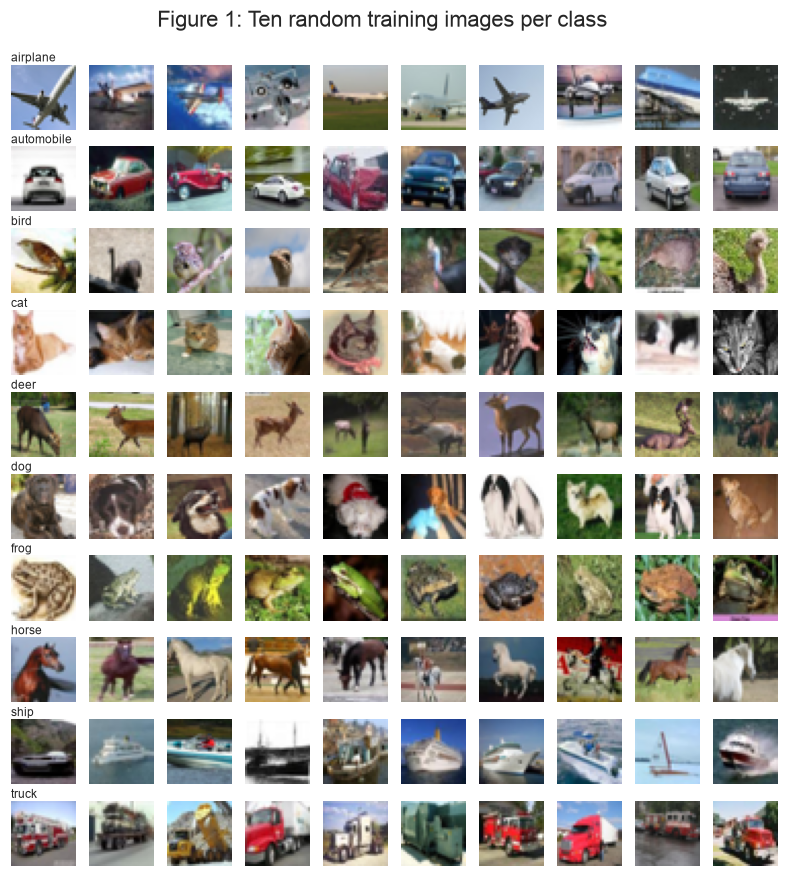

In [5]:
# show counts per class (train and test) 
bal = pd.DataFrame(
    {
        "train": np.bincount(y_train), 
        "test": np.bincount(y_test)
        }, 
        index=CLASSES
    )
display(bal.T)

# sample grid to show 10 random images per class
fig, axes = plt.subplots(10, 10, figsize=(9, 9.5))
for c, row in enumerate(axes):
    idx = rng.choice(np.where(y_train == c)[0], 10, replace=False)
    for j, ax in enumerate(row):
        ax.imshow(X_train[idx[j]]); ax.axis("off")
    row[0].set_title(CLASSES[c], loc="left", fontsize=8, pad=2)
fig.suptitle("Figure 1: Ten random training images per class", y=0.93)
plt.show()

,mean,std
R,0.49,0.25
G,0.48,0.24
B,0.45,0.26


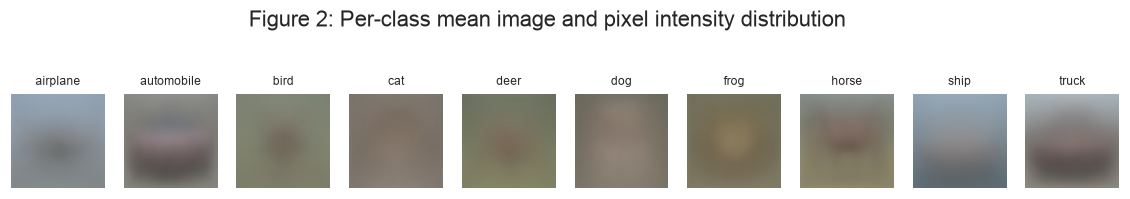

      airplane  automobile  bird   cat  deer   dog  frog  horse  ship  truck
mean      0.56        0.46  0.47  0.46  0.44  0.46  0.42   0.47  0.52   0.49
std       0.14        0.12  0.13  0.13  0.11  0.11  0.12   0.10  0.11   0.10


In [6]:
# average pixel value per colour - Red/Green/Blue 
pixels = 255
X = X_train.astype("float32") / pixels
channel = pd.DataFrame({"mean": X.mean((0, 1, 2), dtype="float64"), "std": X.std((0, 1, 2), dtype="float64")}, index=["R", "G", "B"])
display(channel.round(2))

# plot the average pixel density per class to see if any dominant colour profiles are associated with any of the classes 
fig, axes = plt.subplots(1, 10, figsize=(13, 1.9))
for c in range(10):
    axes[c].imshow(X[y_train == c].mean(0)); axes[c].set_title(CLASSES[c], fontsize=8); axes[c].axis("off")
fig.suptitle("Figure 2: Per-class mean image and pixel intensity distribution", y=1.12)
plt.show()

# brightness, per class (mean and std)
bright = X.mean((1, 2, 3))
print(pd.Series(bright).groupby(y_train).agg(["mean", "std"]).set_axis(CLASSES).round(2).T)

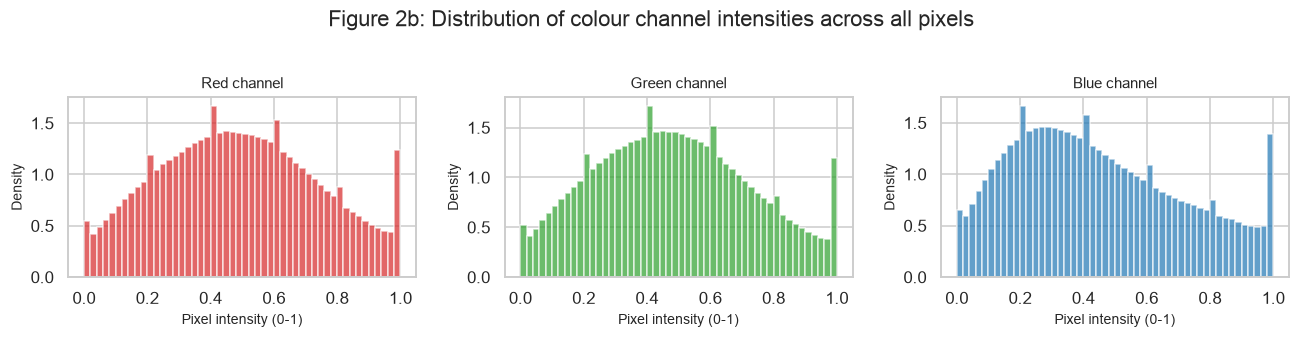

In [7]:
# pixel density across colour channels; RGB
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for i, (ch, color, title) in enumerate([(0, "tab:red", "Red"), (1, "tab:green", "Green"), (2, "tab:blue", "Blue")]):
    axes[i].hist(X[..., i].ravel(), bins=50, color=color, alpha=0.7, density=True)
    axes[i].set_title(f"{title} channel", fontsize=10)
    axes[i].set_xlabel("Pixel intensity (0-1)", fontsize=9)
    axes[i].set_ylabel("Density", fontsize=9)
fig.suptitle("Figure 2b: Distribution of colour channel intensities across all pixels", y=1.02)
plt.tight_layout()
plt.show()

**Findings and preprocessing decisions:**
- *Data quality:* 
    - no missing values or duplicates 
    - Classes are perfectly balanced (5,000 train / 1,000 test each), so accuracy is meaningful and no resampling is needed
- *Weak raw-pixel signal:* 
    - mean images (Figure 2) show blurred blobs with faint colour hues (eg: blue-grey for aeroplane and ship, green for deer and frog). 
    - the per-class brightness overlaps heavily and within-class variability is large - ie. the light and dark levels are too inconsistent within each class and too similar across different classes for simple models to work well
- *Preprocessing:* 
    - scale to [0, 1] (divide by the pixel value, 255) 
    - flatten the existing 3,072 features (32 * 32 * 3) to get meaningful feature representations 
    - note: only standardise using training-set statistics, as PCA is variance-driven and scale-sensitive (Jolliffe and Cadima, 2016)

In [8]:
# scale [0,1], and standardise with trainning data only (no test leakage)
scaled_train = X_train.reshape(len(X_train), -1).astype("float32") / pixels
scaled_test = X_test.reshape(len(X_test), -1).astype("float32") / pixels
mu, sd = scaled_train.mean(0), scaled_train.std(0)
Z_train, Z_test = (scaled_train - mu) / sd, (scaled_test - mu) / sd

print(f"Data shape - Z_train: {Z_train.shape}, Z_test: {Z_test.shape}")
print(f"Scaled training data - mean={Z_train.mean():.2f}, std={Z_train.std():.2f}")

Data shape - Z_train: (50000, 3072), Z_test: (10000, 3072)
Scaled training data - mean=-0.00, std=1.00


## Part B: Dimensionality Reduction (PCA) and Clustering


### 1. PCA

In [9]:
# TODO: check rendering functionality - initially not available when saving and coming back
# this seemed to work: https://plotly.com/python/renderers/ 
pio.renderers.default = "notebook"  # to render offline


def components_for_variance(cum: np.ndarray,
                            thresholds: tuple[float, ...] = (0.8, 0.9, 0.95, 0.99)) -> dict[str, int]:
    """Return the number of principal components needed to reach each variance threshold.

    Parameters
    ----------
    cum : np.ndarray
        Cumulative explained-variance ratio from PCA, one value per component.
        It must be non-decreasing and end near 1.0 (e.g. ``np.cumsum(pca.explained_variance_ratio_)``).
    thresholds : tuple[float, ...], default (0.8, 0.9, 0.95, 0.99)
        Cumulative-variance targets, between 0 and 1.

    Returns
    -------
    dict[str, int]
        Maps each threshold label (e.g. 0.95 --> "95%") to the smallest number of components
        whose cumulative variance is at least that threshold.

    Notes
    -----
    ``np.searchsorted`` returns the index of the first entry at or above the threshold,
    so adding 1 converts that zero-based index into a count of components.
    If a threshold is above the largest value in ``cum``, the function returns
    ``len(cum) + 1``, which is more than the number of components available.
    """
    return {f"{t:.0%}": int(np.searchsorted(cum, t) + 1) for t in thresholds}


def plot_pca_overview(pca: PCA, Z: np.ndarray, y: np.ndarray, class_names: list[str],
                      n_curve: int = 500, n_points: int = 5000, target: float = 0.95) -> go.Figure:
    """Plot cumulative explained variance and the projection onto PC1/PC2 
    (ie. how much of the information is captured by selected components)

    Args:
        pca: PCA already fitted on the standardised training pixels
        Z: Standardised feature matrix, shape (n_samples, n_features).
        y: Integer class labels aligned with ``Z``.
        class_names: Class names indexed by label.
        n_curve: Number of components shown on the variance curve.
        n_points: Number of images projected in the scatter.
        target: Variance threshold to annotate.

    Returns:
        2 Plotly graphs: components x variance, and PC1 x PC2.
    """
    cum = np.cumsum(pca.explained_variance_ratio_)
    n_target = int(np.searchsorted(cum, target) + 1)
    proj = pca.transform(Z[:n_points])[:, :2]
    labels = y[:n_points]

    fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.1, subplot_titles=(
        f"Retaining {target:.0%} variance needs {n_target} components",
        f"First two components ({n_points:,} training images)"))

    # graph 1: cumulative explained variance
    k = np.arange(1, min(n_curve, cum.size) + 1)
    fig.add_trace(go.Scatter(x=k, y=cum[:k.size], mode="lines", showlegend=False,
                             hovertemplate="Components: %{x}<br>Variance: %{y:.1%}<extra></extra>"),
                  row=1, col=1)
    fig.add_hline(y=target, line_dash="dash", line_color="grey", row=1, col=1)
    fig.add_vline(x=n_target, line_dash="dash", line_color="grey", row=1, col=1)

    # graph 2: PCs - legend uses one trace per class
    palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd",
               "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]
    for c, name in enumerate(class_names):
        m = labels == c
        fig.add_trace(go.Scattergl(
            x=proj[m, 0], y=proj[m, 1], mode="markers", name=name,
            marker=dict(size=4, opacity=0.6, color=palette[c % len(palette)]),
            hovertemplate=f"{name}<br>PC1: %{{x:.2f}}<br>PC2: %{{y:.2f}}<extra></extra>"),
            row=1, col=2)

    fig.update_xaxes(title_text="Number of components", row=1, col=1)
    fig.update_yaxes(title_text="Cumulative explained variance", tickformat=".0%", row=1, col=1)
    fig.update_xaxes(title_text="PC1", row=1, col=2)
    fig.update_yaxes(title_text="PC2", row=1, col=2)
    fig.update_layout(title="Figure 3: PCA on standardised pixels", template="plotly_white",
                      width=1100, height=420, legend=dict(title="Class", itemsizing="constant"))
    return fig


# plotting
pca_full = PCA(random_state=RANDOM_STATE).fit(Z_train)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.searchsorted(cum, 0.95) + 1)
print("Components for variance:", components_for_variance(cum))
plot_pca_overview(pca_full, Z_train, y_train, CLASSES).show()

Components for variance: {'80%': 35, '90%': 103, '95%': 221, '99%': 662}


In [ ]:
# keep the components explaining 95% of variance
pca = PCA(n_components=n95, random_state=RANDOM_STATE).fit(Z_train)

# transform current train annd test set using the normalised scores 
P_train, P_test = pca.transform(Z_train), pca.transform(Z_test)
print(f"{Z_train.shape[1]} -> {n95} dimensions ({n95 / Z_train.shape[1]:.1%} of original)")

3072 -> 221 dimensions (7.2% of original)


### k-means: choosing `k` and fitting

- Used k-means to group PCA scores into clusters (Cornell University, 2022)
- Applied the elbow and silhouette methods, however, there is no best fit.
- Therefore, selected $k = 10$ matching the ten known classes. 
- To evaluate how well these unsupervised clusters mapped to the true classes, they were scored against the ground-truth labels using the Adjusted Rand Index (ARI; Hubert & Arabie, 1985) and Normalized Mutual Information (NMI; Scikit Learn, 2026b).

,k,inertia,silhouette
0,2,120005880.0,0.158496
1,3,111563040.0,0.107355
2,4,104981128.0,0.098093
3,5,102013552.0,0.077160
4,6,99495928.0,0.070581
5,7,97308208.0,0.071025
6,8,95601400.0,0.060344
7,9,94170464.0,0.058566
8,10,92992560.0,0.050212
9,11,91907752.0,0.051164


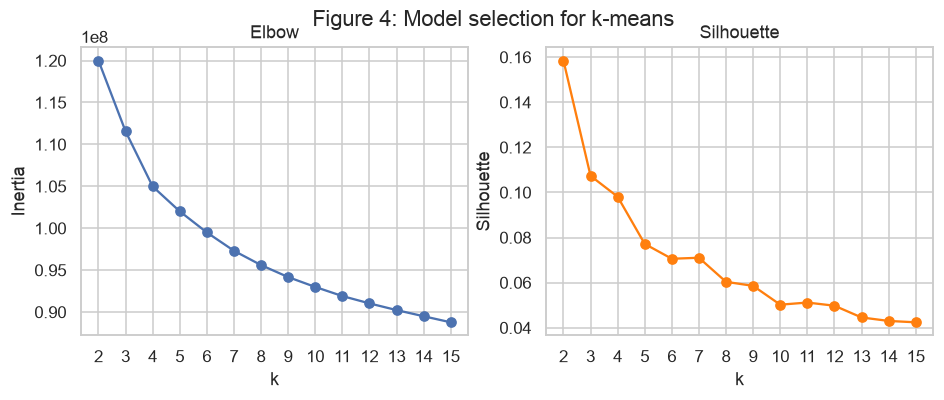

In [12]:
ks = range(2, 16)
# randomly selects 10_000 samples to approximate the silhouette score
sil_idx = rng.choice(len(P_train), 10_000, replace=False)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=3, random_state=RANDOM_STATE).fit(P_train)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(P_train[sil_idx], km.labels_[sil_idx]))

# display DF versionn
display(pd.DataFrame({
    'k': list(ks),
    'inertia': inertia,
    'silhouette': sil
})
)

# plotting elbow and silhoutte
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(ks, inertia, "o-"); ax[0].set(xlabel="k", ylabel="Inertia", title="Elbow")
ax[0].set_xticks(ks)
ax[1].plot(ks, sil, "o-", c="tab:orange"); ax[1].set(xlabel="k", ylabel="Silhouette", title="Silhouette")
ax[1].set_xticks(ks)
fig.suptitle("Figure 4: Model selection for k-means") 
plt.show()

,ARI,NMI,"silhouette (train, 10_000 sample)"
train,0.04,0.08,0.051
test,0.04,0.08,NaN


Cluster purity (train): 21.9% 


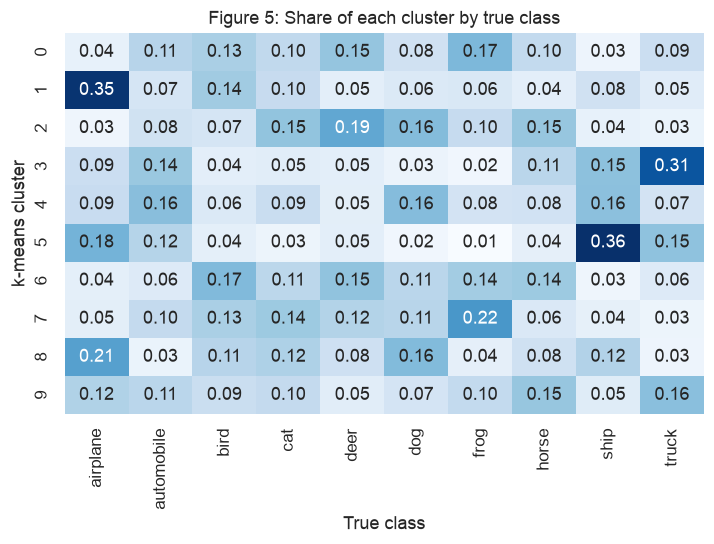

In [ ]:
km = KMeans(n_clusters=10, n_init=10, random_state=RANDOM_STATE).fit(P_train)
test_clusters = km.predict(P_test)


# measure match between true vs predicted groups - ARI: 0 = random guessing, 1 = perfect match
# measure shared information the predicted groups hold about the real classes: NMI: 0 = no overlap, 1 = perfect overlap
metrics = pd.DataFrame({
    "ARI": [adjusted_rand_score(y_train, km.labels_), adjusted_rand_score(y_test, test_clusters)],
    "NMI": [normalized_mutual_info_score(y_train, km.labels_), normalized_mutual_info_score(y_test, test_clusters)],
}, index=["train", "test"]).round(2)

# set NaN for test since it was never run 
metrics["silhouette (train, 10_000 sample)"] = [round(silhouette_score(P_train[sil_idx], km.labels_[sil_idx]), 3), np.nan]

# share of each cluster made of each class 
ct = pd.crosstab(km.labels_, y_train).set_axis(CLASSES, axis=1)
# measures data points that are correctly grouped if each cluster is assigned exclusively to its single most common class
purity = ct.max(axis=1).sum() / ct.values.sum()
display(metrics)
print(f"Cluster purity (train): {purity:.1%} ")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.heatmap(ct.div(ct.sum(axis=1), axis=0), annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax)
ax.set(xlabel="True class", ylabel="k-means cluster", title="Figure 5: Share of each cluster by true class")
plt.show()

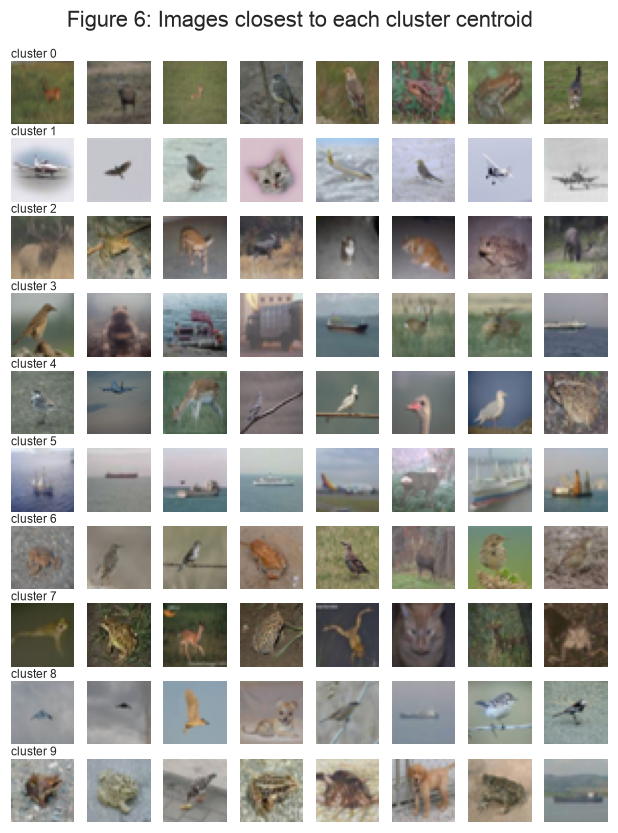

In [ ]:
# Show the training images closest to each centroid
d = km.transform(P_train)   # distance to every centroid

fig, axes = plt.subplots(10, 8, figsize=(7, 9))
for c in range(10):
    nearest = np.argsort(d[:, c])[:8]
    for j in range(8):
        axes[c, j].imshow(X_train[nearest[j]]); axes[c, j].axis("off")
    axes[c, 0].set_title(f"cluster {c}", loc="left", fontsize=8, pad=2)
fig.suptitle("Figure 6: Images closest to each cluster centroid", y=0.93); plt.show()

### Interpretation

- **Clusters follow background and colour, not object class.** 
    - Silhouette falls with k (Figure 4: 0.16 at k=2, 0.05 at k=10) and the elbow is smooth, so there is no natural k. 
    - At k=10, test ARI is 0.04, NMI 0.08 and purity 22% - no cluster exceeds 36% of one class (Figure 5). 
    - Figure 6 shows why; cluster 5 is blue (ship, aeroplane), cluster 1 pale grey, while clusters 0, 2 and 7 are green or brown backgrounds mixing deer, frog, bird and cat. 
    - Therefore, Pixel PCA captures global colour and brightness rather than shape. 

- **Unsupervised learning is not a suitable classifier** 
    - Instead, it is a useful EDA tool, revealing visual groupings and dataset biases.
    - Moreover, it can reduce  labelling cost by sampling one batch per cluster for annotators 
    - Furthermore, it can perform anomaly or duplicate detection without labels. 

## Part C: Classification Models

* Evaluating the performance across four classifiers on the same standardised 221 PCA scores, 
    - a decision tree (Breiman et al., 1984), 
    - random forest (Breiman, 2001), 
    - Radial Basis Function (RBF) kernel SVM (Cortes and Vapnik, 1995) and 
        * note: I have assumed non-linearity based on the EDA above, therefore using RBF (Scikit-learn, 2026)
    - k-NN (Cover and Hart, 1967). 
* Accuracy and macro-F1 suit balanced classes; train accuracy on a 10,000-image sample exposes overfitting. 
* Note: hyperparameters have not been tuned - this can be part of future work

In [ ]:
def evaluate_models(models, X_train, y_train, X_test, y_test, model_dir, file_names):
    """Fit or load each classifier, then score it on the same test set.

    Parameters
    ----------
    models : dict[str, estimator]
        Unfitted scikit-learn estimators, keyed by display name.
    X_train, y_train, X_test, y_test : np.ndarray
        Training and test features and labels.
    model_dir : pathlib.Path
        Folder for saved .joblib models and fit_times.json. Created if missing.
    file_names : dict[str, str]
        Maps each display name to its saved file stem, e.g. "svm_rbf".

    Returns
    -------
    results : pd.DataFrame
        One row per model with train accuracy (10k sample), test accuracy,
        test macro-F1, fit time and predict time.
    preds : dict[str, np.ndarray]
        Test-set predictions, keyed by display name.
    """
    model_dir.mkdir(exist_ok=True)
    times_path = model_dir / "fit_times.json"
    saved_times = json.loads(times_path.read_text()) if times_path.exists() else {}

    print(f"Evaluating {len(models)} models (saved models in {model_dir})")
    run_start = time.perf_counter()
    rows, preds = [], {}
    for i, (name, model) in enumerate(models.items(), start=1):
        print(f"\n[{i}/{len(models)}] {name}")
        path = model_dir / f"{file_names[name]}.joblib"
        if path.exists():
            model = joblib.load(path)  # reuse the saved model, skip training
            fit_s = saved_times.get(name, float("nan"))
            print(f"  loaded {path.name} (original fit time {fit_s:.1f}s)")
        else:
            print(f"  no saved model found, training on {len(X_train):,} images...")
            t0 = time.perf_counter(); model.fit(X_train, y_train); fit_s = time.perf_counter() - t0
            joblib.dump(model, path)
            saved_times[name] = fit_s
            print(f"  trained in {fit_s:.1f}s and saved to {path.name}")

        print(f"  predicting on {len(X_test):,} test images...")
        t0 = time.perf_counter(); pred = model.predict(X_test); pred_s = time.perf_counter() - t0
        preds[name] = pred
        row = {"model": name,
               "train acc (10k sample)": model.score(X_train[:10000], y_train[:10000]),
               "test acc": accuracy_score(y_test, pred),
               "test macro-F1": f1_score(y_test, pred, average="macro"),
               "fit time (s)": fit_s, "predict time (s)": pred_s}
        rows.append(row)
        print(f"  test acc {row['test acc']:.3f} | macro-F1 {row['test macro-F1']:.3f} | predict {pred_s:.1f}s")

    times_path.write_text(json.dumps(saved_times, indent=2))
    results = pd.DataFrame(rows).set_index("model")
    print(f"\nDone: {len(models)} models in {time.perf_counter() - run_start:.0f}s")
    return results, preds


In [ ]:
models = {
    "Decision tree": DecisionTreeClassifier(max_depth=12, random_state=RANDOM_STATE),
    "Random forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(kernel="rbf", C=5, gamma="scale"),
    "k-NN (k=15)": KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
}

MODEL_DIR = DATA_DIR.parent / "models"
FILE_NAMES = {
    "Decision tree": "decision_tree", 
    "Random forest": "random_forest",
    "SVM (RBF)": "svm_rbf",  # RBF assumption - given EDA above, I assume classes are not linearly separable
    "k-NN (k=15)": "knn_k15"
    }


# same train/test split and standardised PCA scores from previous section 
results, preds = evaluate_models(
    models, 
    P_train, 
    y_train, 
    P_test, 
    y_test, 
    MODEL_DIR, 
    FILE_NAMES
    )

results.round(2)


Evaluating 4 models (saved models in models)

[1/4] Decision tree
  no saved model found, training on 50,000 images...
  trained in 18.3s and saved to decision_tree.joblib
  predicting on 10,000 test images...
  test acc 0.306 | macro-F1 0.304 | predict 0.0s

[2/4] Random forest
  no saved model found, training on 50,000 images...
  trained in 51.2s and saved to random_forest.joblib
  predicting on 10,000 test images...
  test acc 0.458 | macro-F1 0.452 | predict 0.5s

[3/4] SVM (RBF)
  no saved model found, training on 50,000 images...
  trained in 902.9s and saved to svm_rbf.joblib
  predicting on 10,000 test images...
  test acc 0.574 | macro-F1 0.573 | predict 134.7s

[4/4] k-NN (k=15)
  no saved model found, training on 50,000 images...
  trained in 0.0s and saved to knn_k15.joblib
  predicting on 10,000 test images...
  test acc 0.365 | macro-F1 0.353 | predict 4.2s

Done: 4 models in 1255s


,train acc (10k sample),test acc,test macro-F1,fit time (s),predict time (s)
model,,,,,
Decision tree,0.50,0.31,0.30,18.34,0.00
Random forest,1.00,0.46,0.45,51.22,0.46
SVM (RBF),0.91,0.57,0.57,902.92,134.74
k-NN (k=15),0.43,0.37,0.35,0.02,4.17


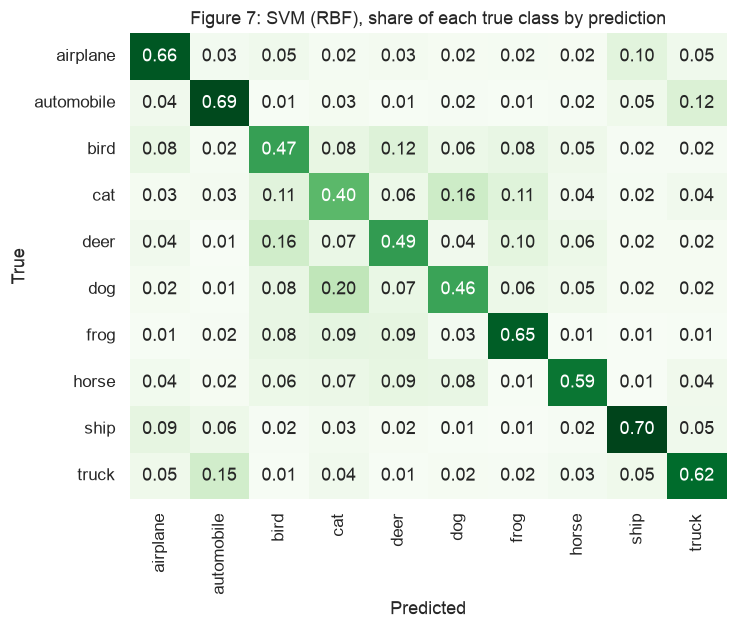

Lowest-recall classes: {'cat': np.float64(0.4), 'dog': np.float64(0.46), 'bird': np.float64(0.47)}


In [41]:
# show per-class recall on the diagonal for the best classical model
best = results["test acc"].idxmax()
cm = confusion_matrix(y_test, preds[best], normalize="true")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Greens", cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set(xlabel="Predicted", ylabel="True", title=f"Figure 7: {best}, share of each true class by prediction")
plt.show()

print(f"Lowest-recall classes: {dict(pd.Series(np.diag(cm), index=CLASSES).nsmallest(3).round(2))}")

**Results.** 
- The SVM is performs best (test accuracy 58%, macro-F1 0.573), followed by random forest (46%), k-NN (37%) and the decision tree (31%). 
- Both the forest and SVM overfit on the training data (100% and 91%, respectively), however, the SVM's RBF boundary generalises slightly better on the test set (57%)
- The tree is weak and unstable, which bagging 200 trees partly fixes whilst k-NN suffers from distance concentration even after PCA (Beyer et al., 1999). - The SVM is costly: about 13 minutes to fit and 2 to predict 10,000 images, versus under a minute for the forest. 
- Figure 7 shows animals are confused most: cat (recall 0.40), dog (0.46) and bird (0.47).

## Part F: Results Summary and Discussion

In [ ]:
summary = pd.DataFrame({
    "Item": [
        "Images (train / test)", 
        "Classes (balanced)", 
        "Raw dimensions", 
        "PCA dims (95% variance)",
        "k-means clusters", 
        "ARI (test)", 
        "NMI (test)", 
        "Cluster purity (train)"
        ],
    "Value": [
        "50,000 / 10,000", 
        10, 
        3072, 
        n95, 
        10, 
        f"{metrics.loc['test','ARI']:.3f}",
        f"{metrics.loc['test','NMI']:.3f}", 
        f"{purity:.1%}"
        ],
}).set_index("Item")
summary

,Value
Item,
Images (train / test),"50,000 / 10,000"
Classes (balanced),10
Raw dimensions,3072
PCA dims (95% variance),221
k-means clusters,10
ARI (test),0.040
NMI (test),0.080
Cluster purity (train),21.9%


In [ ]:
# Figure 8: accuracy vs compute 
fig = make_subplots(rows=1, cols=2,
                    subplot_titles=("Figure 8a: train vs test accuracy",
                                    "Figure 8b: performance vs compute"),
                    horizontal_spacing=0.1)

# Left: grouped bars, train vs test accuracy per model
fig.add_trace(go.Bar(x=results.index, y=results["train acc (10k sample)"], name="train (10k sample)"), row=1, col=1)
fig.add_trace(go.Bar(x=results.index, y=results["test acc"], name="test"), row=1, col=1)

# Right: test macro-F1 against total compute time, with model names beside each point
total_s = results["fit time (s)"] + results["predict time (s)"]
fig.add_trace(go.Scatter(x=total_s, y=results["test macro-F1"], mode="markers+text",
                         text=results.index, textposition="top center",
                         marker=dict(size=12), showlegend=False), row=1, col=2)

# pad the log x-axis (range is in log10 units) so no point sits on the edge
log_t = np.log10(total_s)
fig.update_xaxes(type="log", range=[log_t.min() - 0.4, log_t.max() + 0.4],
                 title_text="Fit + predict time (s, log scale)", row=1, col=2)
fig.update_yaxes(title_text="Accuracy", range=[0, 1], row=1, col=1)
fig.update_yaxes(title_text="Test macro-F1", range=[0, 1], row=1, col=2)
fig.update_xaxes(tickangle=-30, row=1, col=1)  # angled model names so they fit under the bars
fig.update_layout(barmode="group", height=480, width=1100,
                  legend=dict(orientation="h", y=-0.25), margin=dict(b=120))
fig.show()

results[["test acc", "test macro-F1", "fit time (s)"]].round(2)


,test acc,test macro-F1,fit time (s)
model,,,
Decision tree,0.31,0.30,18.34
Random forest,0.46,0.45,51.22
SVM (RBF),0.57,0.57,902.92
k-NN (k=15),0.37,0.35,0.02


**Findings:** 
- The data is clean and balanced. 
- The 3,072 raw dimensions compress to 221 (7.2%) while keeping 95% of variance, but k-means on these scores recovers class structure poorly (test ARI 0.041, NMI 0.081, purity 21.9%) because pixel variance reflects background and colour. 
- Supervised models on the same features perform better but are not robust (Figure 8): SVM = 57.4%, forest = 45.8%, k-NN 36.5%, tree = 30.6%. While SVM takes almost 18 times longer to fit than the forest for 12 points of accuracy.

**Business implications:** 
- No model approaches the 90% recall target, so flat-pixel models cannot automate categorisation - at best the SVM could triage for human review. 
- Clustering remains useful for choosing diverse images to label.
- The weak pixel signal points to CNNs as the next step, weighed against compute cost.

**Limitations:** 
- Models were untuned, one split and seed were used, and 32x32 images are simpler than real product photos.

## Part G: References

Arthur, D. and Vassilvitskii, S. (2007) 'k-means++: the advantages of careful seeding', *Proceedings of the 18th Annual ACM-SIAM Symposium on Discrete Algorithms*, pp. 1027-1035.

Beyer, K., Goldstein, J., Ramakrishnan, R. and Shaft, U. (1999) 'When is "nearest neighbor" meaningful?', *Database Theory - ICDT 1999*, Lecture Notes in Computer Science, vol. 1540, pp. 217-235.

Breiman, L. (2001) 'Random forests', *Machine Learning*, 45(1), pp. 5-32.

Breiman, L., Friedman, J.H., Olshen, R.A. and Stone, C.J. (1984) *Classification and regression trees*. Belmont, CA: Wadsworth.

Cortes, C. and Vapnik, V. (1995) 'Support-vector networks', *Machine Learning*, 20(3), pp. 273-297.

Cover, T. and Hart, P. (1967) 'Nearest neighbor pattern classification', *IEEE Transactions on Information Theory*, 13(1), pp. 21-27.

Hubert, L. and Arabie, P. (1985) 'Comparing partitions', *Journal of Classification*, 2(1), pp. 193-218.

Jolliffe, I.T. and Cadima, J. (2016) 'Principal component analysis: a review and recent developments', *Philosophical Transactions of the Royal Society A*, 374(2065), 20150202.

Krizhevsky, A. (2009) *Learning multiple layers of features from tiny images*. Technical report, University of Toronto.

Lloyd, S. (1982) 'Least squares quantization in PCM', *IEEE Transactions on Information Theory*, 28(2), pp. 129-137.

Pedregosa, F. et al. (2011) 'Scikit-learn: machine learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825-2830.

Rousseeuw, P.J. (1987) 'Silhouettes: a graphical aid to the interpretation and validation of cluster analysis', *Journal of Computational and Applied Mathematics*, 20, pp. 53-65.

Xie, J., Girshick, R. and Farhadi, A. (2016) 'Unsupervised deep embedding for clustering analysis', *Proceedings of the 33rd International Conference on Machine Learning*, PMLR 48, pp. 478-487.